In [ ]:
! pip install pandas numpy matplotlib seaborn statsmodels pmdarima

  Using cached statsmodels-0.15.0-cp311-cp311-win_amd64.whl.metadata (9.6 kB)
  Using cached pmdarima-2.1.1-cp311-cp311-win_amd64.whl.metadata (8.5 kB)
  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached cython-3.3.0-cp311-cp311-win_amd64.whl.metadata (28 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   -- ------------------------------------- 0.8/11.4 MB 11.2 MB/s eta 0:00:01
   -------------- ------------------------- 4.2/11.4 MB 16.8 MB/s eta 0:00:01
   ------------------ --------------------- 5.2/11.4 MB 11.0 MB/s eta 0:00:01
   -------------------- ------------------- 5.8/11.4 MB 8.6 MB/s eta 0:00:01
   --------------------- ------------------ 6.0/11.4 MB 7.5 MB/s eta 0:00:01
   ----------------------- ---------------- 6.6/11.4 MB 6.2 MB/s eta 0:00:01
   ------------------------ -----------


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   -----------------

  Using cached statsmodels-0.15.0-cp311-cp311-win_amd64.whl.metadata (9.6 kB)
  Using cached pmdarima-2.1.1-cp311-cp311-win_amd64.whl.metadata (8.5 kB)
  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached cython-3.3.0-cp311-cp311-win_amd64.whl.metadata (28 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   -----------


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached statsmodels-0.15.0-cp311-cp311-win_amd64.whl.metadata (9.6 kB)
  Using cached pmdarima-2.1.1-cp311-cp311-win_amd64.whl.metadata (8.5 kB)
  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached cython-3.3.0-cp311-cp311-win_amd64.whl.metadata (28 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   -----------


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [35]:
# Import necessary packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from pmdarima import auto_arima
from datetime import datetime

In [6]:
# Set plotting style
sns.set(style="whitegrid", palette="muted")


In [7]:
stock_train_df = pd.read_csv("Googl.csv")

In [8]:
print("Data Preview:")
display(stock_train_df.head())

print("\nDataset Info:")
stock_train_df.info()

print("\nMissing Values:")
print(stock_train_df.isnull().sum())


Data Preview:


,Date,Open,High,Low,Close,Adj Close,Volume
0,2023-01-03,89.589996,91.050003,88.519997,89.120003,89.120003,28131200
1,2023-01-04,90.349998,90.650002,87.269997,88.080002,88.080002,34854800
2,2023-01-05,87.470001,87.570000,85.900002,86.199997,86.199997,27194400
3,2023-01-06,86.790001,87.690002,84.860001,87.339996,87.339996,41381500
4,2023-01-09,88.360001,90.050003,87.860001,88.019997,88.019997,29003900



Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 143 entries, 0 to 142
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       143 non-null    str    
 1   Open       143 non-null    float64
 2   High       143 non-null    float64
 3   Low        143 non-null    float64
 4   Close      143 non-null    float64
 5   Adj Close  143 non-null    float64
 6   Volume     143 non-null    int64  
dtypes: float64(5), int64(1), str(1)
memory usage: 9.3 KB

Missing Values:
Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64


In [9]:
stock_train_df.shape 

(143, 7)

In [11]:
stock_train_df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2023-01-03,89.589996,91.050003,88.519997,89.120003,89.120003,28131200
1,2023-01-04,90.349998,90.650002,87.269997,88.080002,88.080002,34854800
2,2023-01-05,87.470001,87.570000,85.900002,86.199997,86.199997,27194400
3,2023-01-06,86.790001,87.690002,84.860001,87.339996,87.339996,41381500
4,2023-01-09,88.360001,90.050003,87.860001,88.019997,88.019997,29003900


In [12]:
stock_train_df.tail()


,Date,Open,High,Low,Close,Adj Close,Volume
138,2023-07-24,121.660004,123.000000,120.980003,121.529999,121.529999,29686100
139,2023-07-25,121.360001,123.150002,121.019997,122.209999,122.209999,52509600
140,2023-07-26,130.070007,130.979996,128.320007,129.270004,129.270004,61682100
141,2023-07-27,131.669998,133.240005,128.789993,129.399994,129.399994,44952100
142,2023-07-28,130.779999,133.740005,130.570007,132.580002,132.580002,36572900


In [13]:
stock_train_df.describe()

,Open,High,Low,Close,Adj Close,Volume
count,143.000000,143.000000,143.000000,143.000000,143.000000,1.430000e+02
mean,107.461259,109.036644,106.351678,107.782168,107.782168,3.669292e+07
std,12.704584,12.799080,12.610591,12.620808,12.620808,1.415642e+07
min,85.980003,87.570000,84.860001,86.199997,86.199997,1.446790e+07
25%,95.509998,97.625000,94.494999,96.525002,96.525002,2.770280e+07
50%,105.470001,106.690002,104.110001,105.410004,105.410004,3.326680e+07
75%,120.690002,122.305001,119.315002,120.694999,120.694999,4.093580e+07
max,131.669998,133.740005,130.570007,132.580002,132.580002,1.194550e+08


In [14]:
stock_train_df.columns

Index(['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume'], dtype='str')

In [15]:


# Ensure the 'Date' column exists and is in datetime format
if 'Date' in stock_train_df.columns:
    stock_train_df['Date'] = pd.to_datetime(stock_train_df['Date'])
else:
    raise ValueError("No 'Date' column found in the dataset!")


In [16]:
# Sort by date
stock_train_df = stock_train_df.sort_values('Date')

In [17]:
# Set 'Date' as index for time series analysis
stock_train_df.set_index('Date', inplace=True)

In [18]:
# Display summary
display(stock_train_df.head())


,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2023-01-03,89.589996,91.050003,88.519997,89.120003,89.120003,28131200
2023-01-04,90.349998,90.650002,87.269997,88.080002,88.080002,34854800
2023-01-05,87.470001,87.570000,85.900002,86.199997,86.199997,27194400
2023-01-06,86.790001,87.690002,84.860001,87.339996,87.339996,41381500
2023-01-09,88.360001,90.050003,87.860001,88.019997,88.019997,29003900


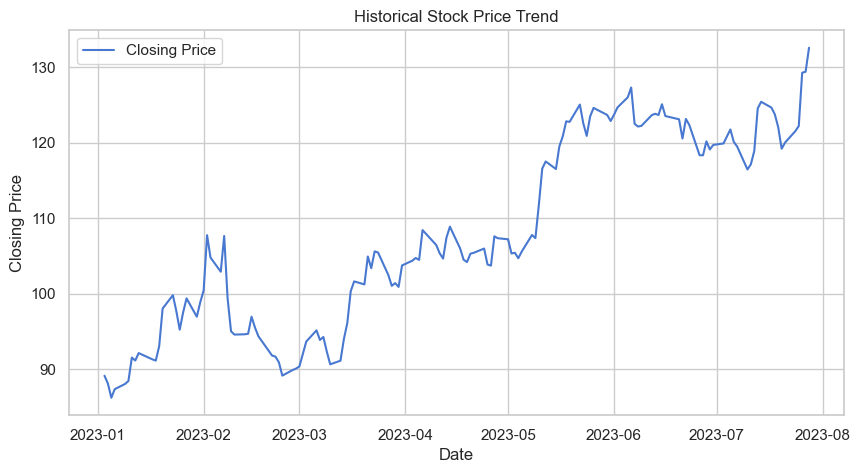

In [19]:
# visualizations
plt.figure(figsize=(10,5))
plt.plot(stock_train_df.index, stock_train_df['Close'], label='Closing Price')
plt.title("Historical Stock Price Trend")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.show()


In [20]:
# Calculate moving averages
stock_train_df['MA_20'] = stock_train_df['Close'].rolling(window=20).mean()
stock_train_df['MA_50'] = stock_train_df['Close'].rolling(window=50).mean()
stock_train_df['EMA_20'] = stock_train_df['Close'].ewm(span=20, adjust=False).mean()


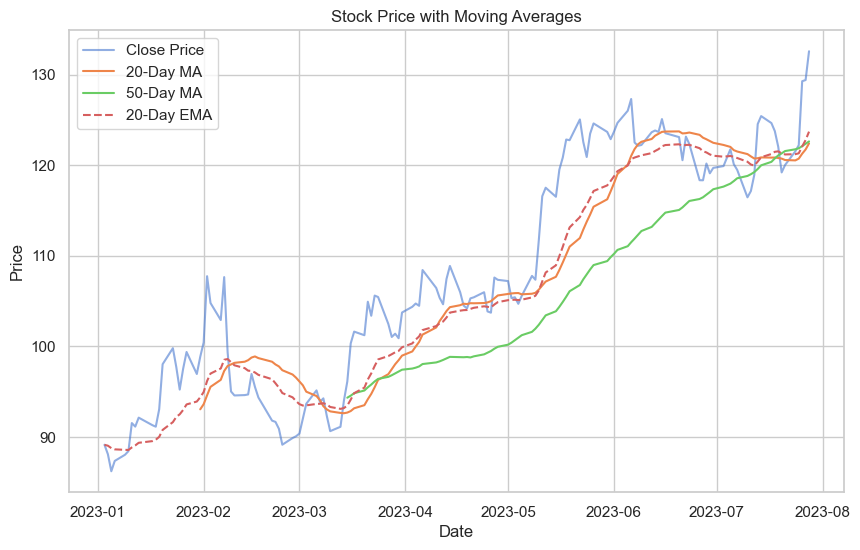

In [21]:
# Plot
plt.figure(figsize=(10,6))
plt.plot(stock_train_df['Close'], label='Close Price', alpha=0.6)
plt.plot(stock_train_df['MA_20'], label='20-Day MA')
plt.plot(stock_train_df['MA_50'], label='50-Day MA')
plt.plot(stock_train_df['EMA_20'], label='20-Day EMA', linestyle='--')
plt.title("Stock Price with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.show()


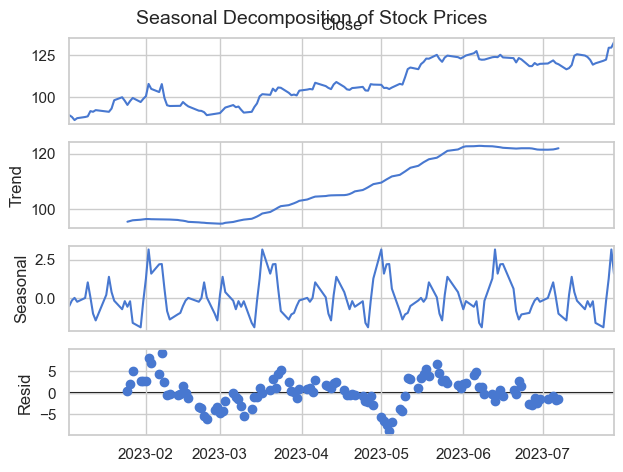

In [22]:
# Decompose time series to see trend, seasonality, and residuals
result = seasonal_decompose(stock_train_df['Close'], model='additive', period=30)
result.plot()
plt.suptitle("Seasonal Decomposition of Stock Prices", fontsize=14)
plt.show()

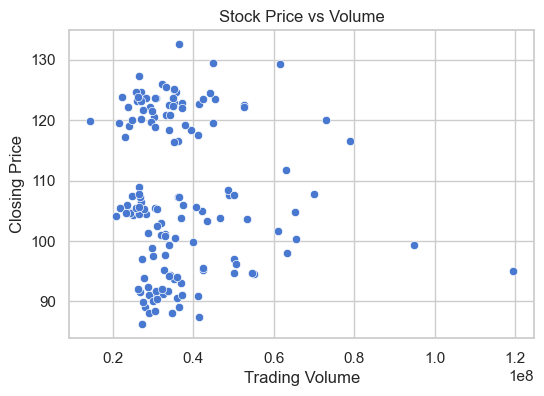

Correlation Matrix:
            Close    Volume
Close   1.000000 -0.059933
Volume -0.059933  1.000000


In [23]:
# Check if Volume column exists
if 'Volume' in stock_train_df.columns:
    plt.figure(figsize=(6,4))
    sns.scatterplot(x=stock_train_df['Volume'], y=stock_train_df['Close'])
    plt.title("Stock Price vs Volume")
    plt.xlabel("Trading Volume")
    plt.ylabel("Closing Price")
    plt.show()

    corr = stock_train_df[['Close', 'Volume']].corr()
    print("Correlation Matrix:\n", corr)
else:
    print("No 'Volume' column found — skipping correlation analysis.")


In [24]:
# Split last 20% for testing
split = int(len(stock_train_df) * 0.8)
train = stock_train_df['Close'][:split]
test = stock_train_df['Close'][split:]

print(f"Training data points: {len(train)}")
print(f"Testing data points: {len(test)}")


Training data points: 114
Testing data points: 29


In [25]:
# Reset index of training and testing data
train = train.reset_index(drop=True)
test = test.reset_index(drop=True)

# Assign numeric index
train.index = pd.RangeIndex(start=0, stop=len(train))
test.index = pd.RangeIndex(start=len(train), stop=len(train) + len(test))

In [26]:
model = ARIMA(train, order=(1, 1, 1))
model_fit = model.fit()

In [27]:
# Forecast
forecast_steps = len(test)

forecast = model_fit.forecast(steps=forecast_steps)

# Convert forecast into Series
forecast = pd.Series(forecast, index=test.index)

print(forecast)

114    124.708556
115    125.055768
116    124.739713
117    125.027408
118    124.765528
119    125.003908
120    124.786919
121    124.984437
122    124.804643
123    124.968304
124    124.819329
125    124.954936
126    124.831497
127    124.943859
128    124.841580
129    124.934681
130    124.849934
131    124.927077
132    124.856856
133    124.920776
134    124.862592
135    124.915555
136    124.867345
137    124.911229
138    124.871282
139    124.907644
140    124.874545
141    124.904674
142    124.877249
Name: predicted_mean, dtype: float64


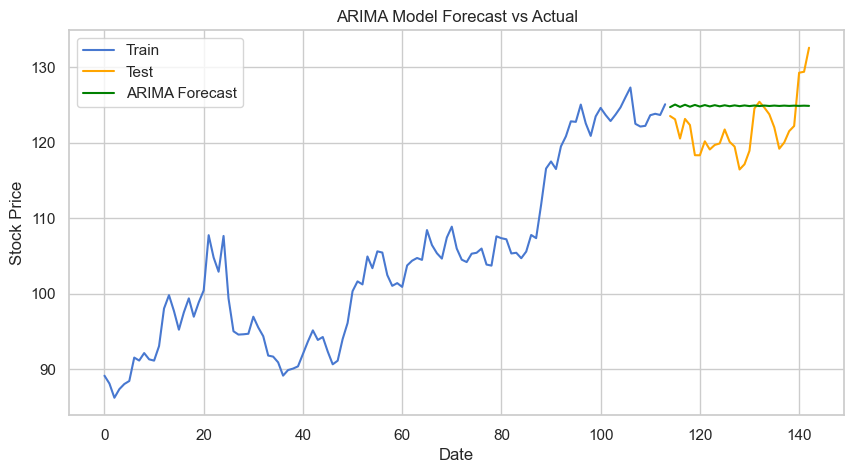

In [28]:
# Plot actual vs predicted
plt.figure(figsize=(10,5))
plt.plot(train, label='Train')
plt.plot(test, label='Test', color='orange')
plt.plot(test.index, forecast, label='ARIMA Forecast', color='green')
plt.title("ARIMA Model Forecast vs Actual")
plt.xlabel("Date")
plt.ylabel("Stock Price")
plt.legend()
plt.show()

In [29]:
# Print summary
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                  114
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -248.380
Date:                Sun, 01 Nov 2026   AIC                            502.761
Time:                        18:54:26   BIC                            510.943
Sample:                             0   HQIC                           506.081
                                - 114                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.9103      0.080    -11.333      0.000      -1.068      -0.753
ma.L1          0.9998      5.324      0.188      0.851      -9.434      11.434
sigma2         4.6745     24.677      0.189      0.8

In [30]:
# Fit Exponential Smoothing model
exp_model = ExponentialSmoothing(train, trend='add', seasonal=None)
exp_fit = exp_model.fit()

In [31]:
# Forecast
exp_forecast = exp_fit.forecast(len(test))

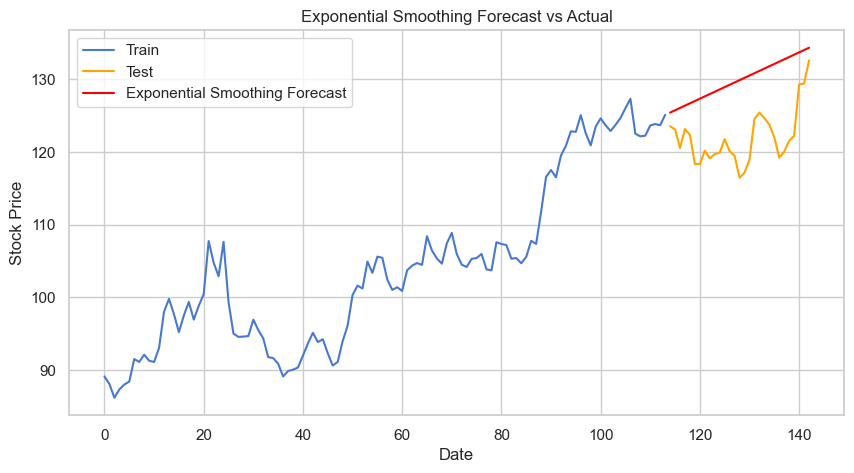

In [32]:
# Plot
plt.figure(figsize=(10,5))
plt.plot(train, label='Train')
plt.plot(test, label='Test', color='orange')
plt.plot(test.index, exp_forecast, label='Exponential Smoothing Forecast', color='red')
plt.title("Exponential Smoothing Forecast vs Actual")
plt.xlabel("Date")
plt.ylabel("Stock Price")
plt.legend()
plt.show()

In [33]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

def evaluate_forecast(actual, predicted, name):
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)
    print(f"{name} Model Performance:")
    print(f"RMSE: {rmse:.2f}")
    print(f"MAE:  {mae:.2f}\n")

evaluate_forecast(test, forecast, "ARIMA")
evaluate_forecast(test, exp_forecast, "Exponential Smoothing")


ARIMA Model Performance:
RMSE: 4.69
MAE:  4.12

Exponential Smoothing Model Performance:
RMSE: 8.61
MAE:  7.91



In [34]:
# Combine forecasts with actual data
results_df = pd.DataFrame({
    "Actual": test.values,
    "ARIMA_Forecast": forecast.values,
    "ExpSmoothing_Forecast": exp_forecast.values
}, index=test.index)

results_df.to_csv("Stock_Price_Forecasts.csv")
print("Forecast results saved as 'Stock_Price_Forecasts.csv'")

Forecast results saved as 'Stock_Price_Forecasts.csv'
